In [23]:
import squidpy as sq
import scanpy as sc
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import cv2
import matplotlib.patches as patches
from matplotlib.patches import Polygon


# --- Helper functions ---
def get_rect(pts):
    pts = pts.astype(np.float32)
    box = cv2.boxPoints(cv2.minAreaRect(pts))
    y_s = box[np.argsort(box[:, 1])]
    t, b = y_s[:2][np.argsort(y_s[:2, 0])], y_s[2:][np.argsort(y_s[2:, 0])]
    return np.array([t[0], t[1], b[1], b[0]], dtype=np.float32)

def plot_HD_and_sc(adata, adata_sc):
    treatment_effect = {
        "nS03": "good",
        "nS01": "poor", 
        "nS02": "poor",
        "nS06": "good",
    }
    
    good_samples = [sample for sample, effect in treatment_effect.items() if effect == "good"]
    poor_samples = [sample for sample, effect in treatment_effect.items() if effect == "poor"]

    all_celltypes = adata.obs['type'].cat.categories.tolist()
    color_map = {
        'B cell': '#ff7f0e',          
        'Endothelial cell': '#1f77b4',
        'Epithelial cell': '#7f7f7f', 
        'Stromal cell': '#9467bd',  
        'Muscle cell': '#8c564b',     
        'Myeloid cell': '#d62728',    
        'Plasma cell': '#bcbd22',     
        'T cell': '#17becf'           
    }
    color_map["Mast cell"] =  "#e377c2"   
    color_map["Schwann cell"] = '#2ca02c'
    
    # Set unified colors
    adata.uns['type_colors'] = [color_map[ct] for ct in all_celltypes]
    adata_sc.uns['type_colors'] = [color_map[ct] for ct in all_celltypes]

    fig = plt.figure(figsize=(9, 12), constrained_layout=True)
    # Adjust grid layout: top 2 rows for spatial transcriptomics plots, bottom 1 row for single-cell and legend
    gs = fig.add_gridspec(
        3, 2,
        height_ratios=[1, 1, 1], width_ratios=[1, 1],
        hspace=-0.0, wspace=-0.0,  # Add a bit of spacing
        left=0.0, right=1.0, top=1.0, bottom=0.0
    )

    # Single-cell UMAP plot (left)
    FONT_SIZE = 12
    umap_ax = fig.add_subplot(gs[2, :1])
    sc.pl.umap(
        adata_sc,
        color='type',
        palette=color_map,
        size=5,
        alpha=1.0,
        show=False,
        ax=umap_ax,
        legend_loc=None
    )
    
    # Remove all spines and ticks
    umap_ax.spines['top'].set_visible(False)
    umap_ax.spines['right'].set_visible(False)
    umap_ax.spines['bottom'].set_visible(False)
    umap_ax.spines['left'].set_visible(False)
    umap_ax.set_xticks([])
    umap_ax.set_yticks([])
    
    # Set axis labels
    umap_ax.set_xlabel('', fontsize=10)
    umap_ax.set_ylabel('', fontsize=10)
    umap_ax.set_title('')
    
    # Get UMAP coordinate range (after plotting)
    xmin, xmax = umap_ax.get_xlim()
    ymin, ymax = umap_ax.get_ylim()
    
    # Unified arrow length (38.2% of the total range)
    arrow_length = (xmax - xmin) * 0.382
    text_offset = arrow_length * 0.18
    
    # Add x-axis arrow and UMAP2 label
    umap2_text = umap_ax.text(2.4 + xmin + text_offset*0.618, ymin, 'UMAP2', 
                              fontsize=FONT_SIZE, ha='center', va='center')
    # No need for plt.draw(), use data coordinates directly
    umap2_end_x = 6.4 + xmin + text_offset*0.618 + len('UMAP2') * 0.1  # Estimate width
    umap_ax.arrow(umap2_end_x, ymin, arrow_length, 0, head_width=arrow_length*0.06, 
                  head_length=arrow_length*0.06, fc='black', ec='black', lw=1.5)
    
    # Add y-axis arrow and UMAP1 label
    umap1_text = umap_ax.text(xmin, 2.5 + ymin + text_offset, 'UMAP1', 
                              fontsize=FONT_SIZE, rotation=90, ha='center', va='center')
    umap1_end_y = 6.5 + ymin + text_offset + len('UMAP1') * 0.1  # Estimate height
    umap_ax.arrow(xmin, umap1_end_y, 0, arrow_length, head_width=arrow_length*0.06, 
                  head_length=arrow_length*0.06, fc='black', ec='black', lw=1.5)
    
    samples = good_samples + poor_samples
    for i, sample in enumerate(samples):
        row = i // 2
        col = i % 2
        ax = fig.add_subplot(gs[row, col])
        
        tp = adata[adata.obs["batch"] == sample].copy()
        current_celltypes = [ct for ct in all_celltypes if ct in tp.obs['type'].values]
        tp.obs['type'] = pd.Categorical(tp.obs['type'], categories=current_celltypes)
        tp.uns['type_colors'] = [color_map[ct] for ct in current_celltypes]
        tp.uns["spatial"] = tp.uns["spatial"][sample] 
        print(tp)
        
        # Get spatial coordinates
        spatial_coords = tp.obsm['spatial']

        r = get_rect(spatial_coords)
        org, ux, uy = r[3], (r[2]-r[3]), (r[0]-r[3])
        M_mat = np.vstack([ux/np.linalg.norm(ux), uy/np.linalg.norm(uy)])
        spatial_coords = (spatial_coords - org) @ M_mat.T
        
        # Get color for each point based on 'type' category
        colors = [color_map[ct] for ct in tp.obs['type']]
        
        # Plot scatter
        ax.scatter(
            spatial_coords[:, 0],  # X coordinate
            spatial_coords[:, 1],  # Y coordinate
            c=colors,              # Color
            s=5,                   # Size
            alpha=1.0,             # Alpha
            edgecolors='none',     # Key: remove white border
            linewidth=0            # Ensure no border line width
        )
        
        # Manually add title: top two above, bottom two below
        title_color = 'red' if treatment_effect[sample] == 'poor' else 'green'
        if row == 0:  # Top two subplots
            title_position = 0.97  # Above
            va = 'bottom'
        else:  # Bottom two subplots
            title_position = +0.03  # Below
            va = 'top'

        anno = sample
        ax.text(0.5, title_position, anno, color=title_color, fontweight='bold', fontsize=14,
                ha='center', va=va, transform=ax.transAxes)
        
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel('')
        ax.set_ylabel('')
        for spine in ax.spines.values():
            spine.set_visible(False)
    
    # Add thick horizontal line to separate spatial plots from the single-cell plot below
    line_y = 0.667  # Add horizontal line at 2/3 position
    line = plt.Line2D([0.04, 0.44], [line_y, line_y], color='black', linewidth=2, transform=fig.transFigure)
    fig.add_artist(line)
    line = plt.Line2D([0.56, 0.96], [line_y, line_y], color='black', linewidth=2, transform=fig.transFigure)
    fig.add_artist(line)

    # Legend (right) - ensure it is inside the grid
    legend_ax = fig.add_subplot(gs[2, 1:])
    legend_ax.axis('off')

    legend_handles = []
    all_celltypes = adata_sc.obs['type'].cat.categories.tolist()
    for ct in all_celltypes:
        handle = plt.Line2D([0], [0], marker='o', color='w',
                           markerfacecolor=color_map[ct], markersize=14,
                           linestyle='None', markeredgecolor='black', markeredgewidth=0.5)
        legend_handles.append(handle)

    from matplotlib.font_manager import FontProperties

    # Define title font properties: bold + set size
    title_font = FontProperties()
    title_font.set_size(14)           # Set font size
    title_font.set_weight('bold')     # Bold
    
    legend = legend_ax.legend(
        legend_handles, all_celltypes,
        loc='center',
        fontsize=14,
        frameon=False,           # Remove border
        fancybox=True,
        shadow=False,
        borderpad=0.8,
        columnspacing=1,
        handletextpad=0.5,
        title='Cell Types',
        title_fontproperties=title_font   # Use fontproperties to control title (including size and weight)
    )
    legend.get_frame().set_edgecolor('gray')
    legend.get_frame().set_linewidth(0.8)

    Visium_HD_text = plt.text(0.002, 2, 'Visium-HD', 
                              fontsize=FONT_SIZE+2, ha='center', va='center', color="#E673A6")
    fig.add_artist(Visium_HD_text)

    scRNA_seq_text = plt.text(-0.78, 0.17, 'scRNA-seq\n99223 cells', 
                              fontsize=FONT_SIZE+2, ha='center', va='center', color='#00A8CC')
    fig.add_artist(scRNA_seq_text)
    
    plt.tight_layout()

AnnData object with n_obs × n_vars = 36171 × 18132
    obs: 'batch', 'type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'type_colors'
    obsm: 'spatial'
AnnData object with n_obs × n_vars = 220769 × 18132
    obs: 'batch', 'type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'type_colors'
    obsm: 'spatial'
AnnData object with n_obs × n_vars = 79838 × 18132
    obs: 'batch', 'type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'type_colors'
    obsm: 'spatial'
AnnData object with n_obs × n_vars = 86908 × 18132
    obs: 'batch', 'type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'type_colors'
    obsm: 'spatial'


/tmp/ipykernel_422010/3188601539.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_422010/3188601539.py:212: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


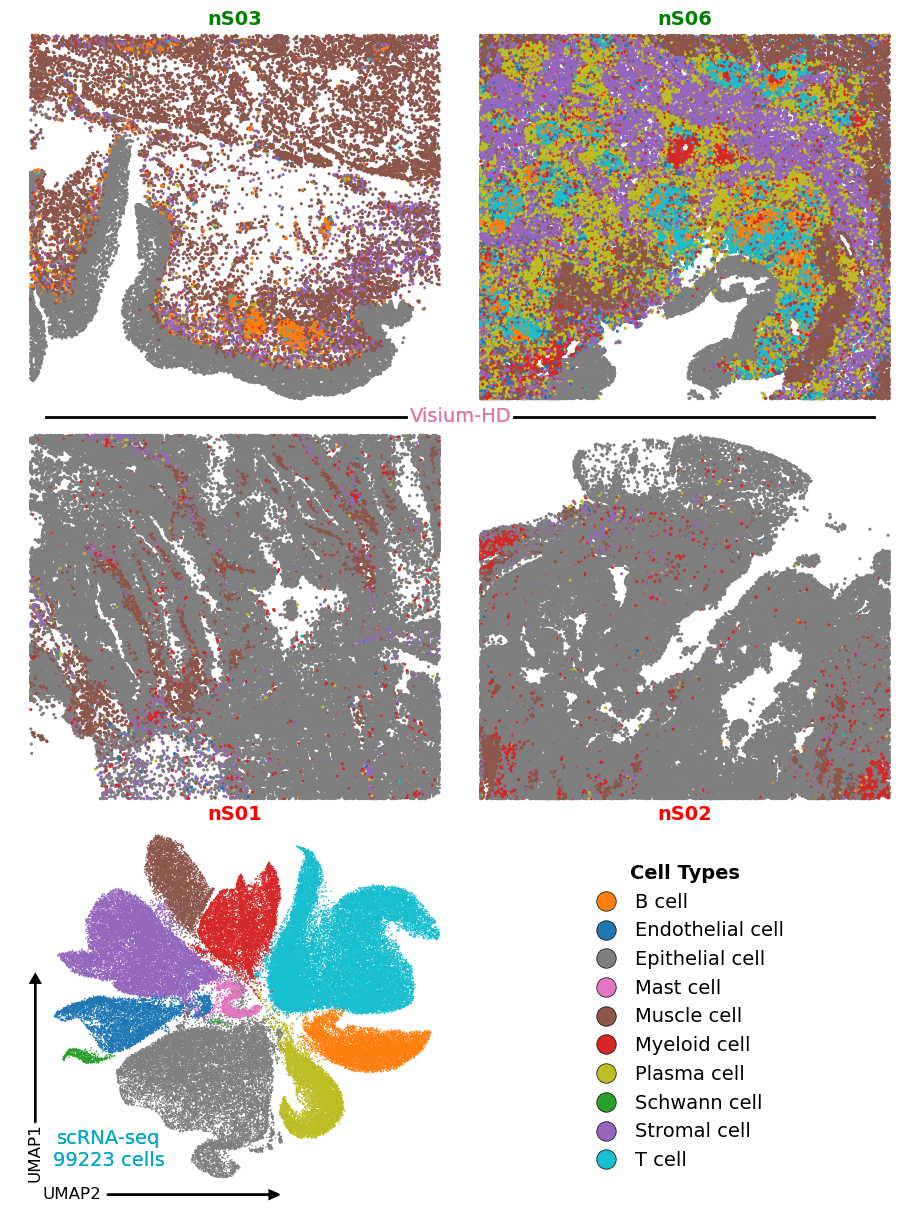

In [24]:
import scanpy as sc
plot_HD_and_sc(sc.read("./h5ad/adata_HD.h5ad"),sc.read("./h5ad/adata_sc.h5ad"))